# Does counted traffic volume belong in the crash models? (#35)

`preprocessing/traffic.py` gives every site the busiest LION segment within 100 ft that DOT's Automated Traffic Volume Counts (`7ym2-wayt`) cover, as average weekday daily traffic. Counts reach few sites, so uncounted sites are filled from a linear fit on road features. #35 asks for coverage and imputation error before the feature goes into a model. This notebook reports both, then runs the NYC Walks tests (`pedestrian_exposure.ipynb`) on the **road-only + pedestrian** model. That model is the EB baseline's shape, where exposure matters most:

1. **Holdout:** does volume improve 2023–25 top-k KSI capture?
2. **Balance:** do speed-camera sites differ in traffic beyond what road features capture?

In [1]:
import logging
import sys
import warnings
from pathlib import Path

sys.path.append("..")
warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.WARNING)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from data.download import download_nycwalks, download_traffic_counts
from model.count_models import NegativeBinomialModel
from preprocessing.panel import FEATURE_SETS, load_panel
from preprocessing.pedestrians import add_pedestrian_features, load_pedestrian_features
from preprocessing.roadway import add_roadway_features, load_roadway_features_by_year
from preprocessing.traffic import add_traffic_features, impute_log_traffic, load_traffic_features
from validation.validate import poisson_deviance, pooled_holdout, top_k_capture
from viz.style import FULL_WIDTH, INK_2, MODEL, MUTED, SURFACE, use_style

use_style()
OUT = Path("outputs/traffic_exposure")
OUT.mkdir(parents=True, exist_ok=True)
SOURCE = "Source: NYC DOT Automated Traffic Volume Counts; MIT City Form Lab NYC Walks; NYPD crashes; DCP LION."
N_BOOT = 500
rng = np.random.default_rng(35)


def source(fig, text=SOURCE):
    """Source line under the lowest drawn element."""
    fig.canvas.draw()
    bottom = fig.get_tightbbox(fig.canvas.get_renderer()).y0 / fig.get_figheight()
    fig.text(0.0, bottom - 0.03, text, fontsize=7.5, color=MUTED, ha="left", va="top")

In [2]:
download_nycwalks()  # both no-op once cached
download_traffic_counts()
panel, scoring, sites = load_panel()
panel = add_roadway_features(panel, load_roadway_features_by_year(sites))
panel = add_pedestrian_features(panel, load_pedestrian_features(sites))
traffic = load_traffic_features(sites)
panel = add_traffic_features(panel, traffic)

F = FEATURE_SETS
IMPUTE_FROM = F["road"] + F["site"]
panel = impute_log_traffic(panel, IMPUTE_FROM)
BASE = F["site"] + F["road"] + F["pedestrian"]

## 1. Coverage: which sites have a count?

In [3]:
counted = traffic.set_index("site_id")["adt"].gt(0)
totals = panel.groupby("site_id").agg(ksi=("ksi", "sum"), speed=("speed_active", "max"))
totals["counted"] = counted.reindex(totals.index).fillna(False).to_numpy()
last = panel[panel["year"] == panel["year"].max()].set_index("site_id")
on = last["traffic_counted"] == 1
pd.Series({
    "sites": f"{len(sites):,}",
    "sites with a counted segment within 100 ft": f"{counted.sum():,}",
    "share of sites": f"{counted.mean():.1%}",
    "share of KSI crashes (panel years) at counted sites": f"{totals.loc[totals['counted'], 'ksi'].sum() / totals['ksi'].sum():.1%}",
    "share of speed-camera sites counted": f"{totals.loc[totals['speed'].astype(bool), 'counted'].mean():.1%}",
    "median weekday daily traffic, counted sites": f"{traffic.loc[traffic['adt'] > 0, 'adt'].median():,.0f}",
    "mean lanes, counted vs all sites": f"{last.loc[on, 'lanes'].mean():.1f} vs {last['lanes'].mean():.1f}",
    "highway share, counted vs all sites": f"{last.loc[on, 'highway'].mean():.0%} vs {last['highway'].mean():.0%}",
})

sites                                                     165,674
sites with a counted segment within 100 ft                  7,405
share of sites                                               4.5%
share of KSI crashes (panel years) at counted sites         11.5%
share of speed-camera sites counted                          9.4%
median weekday daily traffic, counted sites                 7,619
mean lanes, counted vs all sites                       3.7 vs 2.5
highway share, counted vs all sites                    19% vs 10%
dtype: str

## 2. Imputation error

Cross-validated over 5,000 ft spatial blocks, so a site's own segment never trains its fill-in. Error is on the log scale. Counted sites are mostly big roads, so the error on quiet streets is likely larger.

In [4]:
cv = last[on].copy()
xy = sites.set_index("site_id").loc[cv.index, ["x", "y"]]
block = (np.floor(xy["x"] / 5000) * 1e4 + np.floor(xy["y"] / 5000)).to_numpy()
blocks = np.unique(block)
fold_of = dict(zip(blocks, rng.integers(0, 5, len(blocks))))
fold = np.array([fold_of[b] for b in block])
pred = np.empty(len(cv))
for k in range(5):
    masked = cv.assign(log_traffic=cv["log_traffic"].where(fold != k))
    pred[fold == k] = impute_log_traffic(masked, IMPUTE_FROM)["log_traffic_imputed"].to_numpy()[fold == k]
resid = cv["log_traffic"].to_numpy() - pred
r2 = 1 - (resid**2).sum() / ((cv["log_traffic"] - cv["log_traffic"].mean()) ** 2).sum()
print(f"Cross-validated R² {r2:.2f}; median miss ×{np.exp(np.median(np.abs(resid))):.2f}")

Cross-validated R² 0.24; median miss ×1.71


## 3. Holdout: does traffic volume add predictive power?

In [5]:
def scores(y, pred, ks):
    out = {f"top{k}": top_k_capture(y, pred, k) for k in ks}
    out["deviance"] = poisson_deviance(y, pred)
    return out


def site_totals(data, features):
    _, totals = pooled_holdout(lambda: NegativeBinomialModel(features), data)
    return totals.set_index("site_id")


VARIANTS = {
    "Counted flag only": (panel, ["traffic_counted"], (100, 1000)),
    "Imputed volume": (panel, ["log_traffic_imputed"], (100, 1000)),
    "Counted, else imputed, + flag": (panel, ["log_traffic_filled", "traffic_counted"], (100, 1000)),
    "Counted sites only: counted volume": (panel[panel["traffic_counted"] == 1], ["log_traffic"], (100, 500)),
}
rows = []
for name, (data, extra, ks) in VARIANTS.items():
    t0 = site_totals(data, BASE)
    t1 = site_totals(data, BASE + extra).reindex(t0.index)
    y, p0, p1 = t0["ksi"].to_numpy(), t0["pred"].to_numpy(), t1["pred"].to_numpy()
    s0, s1 = scores(y, p0, ks), scores(y, p1, ks)
    draws = []
    for _ in range(N_BOOT):
        i = rng.integers(0, len(y), len(y))
        a, b = scores(y[i], p0[i], ks), scores(y[i], p1[i], ks)
        draws.append({m: b[m] - a[m] for m in a})
    ci = pd.DataFrame(draws).quantile([0.025, 0.975])
    for m in s0:
        rows.append({"variant": name, "metric": m, "without": s0[m], "with_traffic": s1[m],
                     "change": s1[m] - s0[m], "ci_low": ci.loc[0.025, m], "ci_high": ci.loc[0.975, m]})
holdout = pd.DataFrame(rows)
holdout.to_csv(OUT / "holdout.csv", index=False)
holdout.round(4)

,variant,metric,without,with_traffic,change,ci_low,ci_high
0,Counted flag only,top100,0.0084,0.0082,-0.0002,-0.0018,0.0019
1,Counted flag only,top1000,0.0761,0.0789,0.0028,-0.0005,0.0058
2,Counted flag only,deviance,0.2196,0.2191,-0.0004,-0.0007,-0.0002
3,Imputed volume,top100,0.0084,0.0085,0.0001,-0.0002,0.0005
4,Imputed volume,top1000,0.0761,0.0758,-0.0002,-0.0015,0.0012
5,Imputed volume,deviance,0.2196,0.2196,0.0000,0.0000,0.0001
6,"Counted, else imputed, + flag",top100,0.0084,0.0083,-0.0001,-0.0017,0.0026
7,"Counted, else imputed, + flag",top1000,0.0761,0.0788,0.0027,-0.0010,0.0057
8,"Counted, else imputed, + flag",deviance,0.2196,0.2191,-0.0004,-0.0007,-0.0002
9,Counted sites only: counted volume,top100,0.0989,0.0926,-0.0063,-0.0158,0.0057


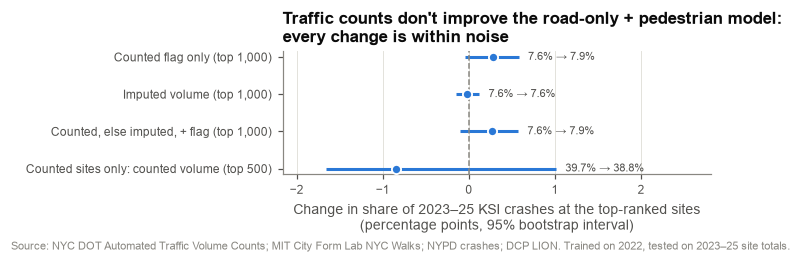

In [6]:
top = holdout[holdout["metric"].isin(["top1000", "top500"])].reset_index(drop=True)
labels = [f"{r.variant} (top {int(r.metric[3:]):,})" for r in top.itertuples()]
fig, ax = plt.subplots(figsize=(FULL_WIDTH, 2.3))
y = np.arange(len(top))
ax.hlines(y, 100 * top["ci_low"], 100 * top["ci_high"], color=MODEL, linewidth=2)
ax.scatter(100 * top["change"], y, color=MODEL, s=36, zorder=3, edgecolor=SURFACE, linewidth=1.2)
for yi, r in zip(y, top.itertuples()):
    ax.annotate(f"{100 * r.without:.1f}% → {100 * r.with_traffic:.1f}%", (100 * r.ci_high, yi),
                xytext=(6, 0), textcoords="offset points", va="center", color=INK_2, fontsize=7.5)
ax.axvline(0, color=MUTED, linestyle="--", linewidth=1)
ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlim(100 * top["ci_low"].min() - 0.5, 100 * top["ci_high"].max() + 1.8)
ax.set(xlabel="Change in share of 2023–25 KSI crashes at the top-ranked sites\n(percentage points, 95% bootstrap interval)")
ax.set_title("Traffic counts don't improve the road-only + pedestrian model:\nevery change is within noise")
fig.tight_layout()
source(fig, SOURCE + " Trained on 2022, tested on 2023–25 site totals.")
fig.savefig(OUT / "1_holdout_change.png")

In [7]:
# KSI per doubling of counted traffic, fit on counted sites before 2023: with site
# features only, then with the full road-only + pedestrian baseline.
train = panel[(panel["traffic_counted"] == 1) & (panel["year"] < 2023)]
doubling = []
for name, features in {"Traffic + site": ["log_traffic"] + F["site"],
                       "Traffic + baseline": BASE + ["log_traffic"]}.items():
    result = NegativeBinomialModel(features).fit(train, train["ksi"], groups=train["site_id"]).result_
    b, (lo, hi) = result.params["log_traffic"], result.conf_int().loc["log_traffic"]
    doubling.append({"model": name, "ratio": 2**b, "ci_low": 2**lo, "ci_high": 2**hi})
pd.DataFrame(doubling).round(2)

,model,ratio,ci_low,ci_high
0,Traffic + site,1.31,1.20,1.44
1,Traffic + baseline,1.05,0.95,1.17


## 4. Balance: do camera sites differ in traffic beyond road features?

Counted sites only. Speed-camera sites had a speed camera at any time; comparison sites never had any camera (#27's buffer isn't applied yet).

In [8]:
site = last.assign(
    speed_site=panel.groupby("site_id")["speed_active"].max().astype(bool),
    camera_any=panel.groupby("site_id")["camera_site"].max().astype(bool),
)
site = site[(site["traffic_counted"] == 1) & (site["speed_site"] | ~site["camera_any"])]
treated = site["speed_site"].to_numpy()
lt = site["log_traffic"].to_numpy()
X = np.column_stack([np.ones(len(site)), site[BASE].astype(float).to_numpy()])
residual = lt - X @ np.linalg.lstsq(X, lt, rcond=None)[0]


def smd(values):
    """Standardized mean difference, camera minus comparison sites."""
    a, b = values[treated], values[~treated]
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)


pd.Series({"speed-camera sites": int(treated.sum()), "comparison sites": int((~treated).sum()),
           "SMD, log traffic": smd(lt),
           "SMD, after road, site and pedestrian features": smd(residual)}).round(3)

speed-camera sites                                231.000
comparison sites                                 7079.000
SMD, log traffic                                    0.092
SMD, after road, site and pedestrian features       0.112
dtype: float64

## 5. Takeaways

- **Don't add traffic volume to the baseline or the risk model.** None of the variants changes 2023–25 top-k KSI capture beyond noise. That covers the counted flag, imputed volume, counted-else-imputed, and counted volume among counted sites only. The counted flag improves deviance by a hair (0.2196 to 0.2191), but it marks where DOT chose to run a study, not how much traffic there is. Imputed volume changes nothing, because it is a linear combination of road features already in the model.
- **Coverage is the binding limit.** Counts reach under 5% of sites, about an eighth of KSI crashes and under a tenth of speed-camera sites, mostly on big roads. A fill-in from road features explains only about a quarter of log volume, and it's built from features the model already has.
- **Road features already carry the exposure signal.** With site features only, volume predicts KSI (about 1.3× per doubling). After road and pedestrian features it's about 1.05×, and the interval includes 1.
- **Balance doesn't call for it either.** Among counted sites, speed-camera and comparison sites differ little in traffic (standardized difference about 0.1 before and after road features), based on about 230 camera sites.
- A source covering every segment (e.g. NYSDOT AADT estimates) would be the only way to revisit this.